# Hifsah CKD — Siamese network: Normal vs Cyst + XAI
## 0. Environment check

In [1]:
import sys, importlib.util
print(sys.version)
print({m: importlib.util.find_spec(m) is not None for m in ['torch', 'torchvision', 'pytorch_grad_cam', 'shap', 'captum', 'sklearn']})

3.9.6 (default, Aug 25 2026, 21:26:21) 
[Clang 21.0.0 (clang-2100.3.34.2)]
{'torch': True, 'torchvision': True, 'pytorch_grad_cam': True, 'shap': True, 'captum': True, 'sklearn': True}


In [2]:
import torch
print(torch.__version__, '| MPS available:', torch.backends.mps.is_available())

2.8.0 | MPS available: True


Install the two missing XAI libraries (run once).

In [3]:
%pip install -q grad-cam captum

Note: you may need to restart the kernel to use updated packages.


## 1. Prepare the data (Normal vs Cyst)
1. Remove exact duplicate files
2. Group neighbouring slices of the same scan, so a scan never ends up in both train and test
3. Split by scan: ~70% train / 15% val / 15% test
4. Save 224×224 grayscale copies (padded to square, not stretched) in `dataset_224/`

In [4]:
import os, hashlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image, ImageOps

SRC, DST = 'dataset', 'dataset_224'
CLASSES = ['Normal', 'Cyst']   # label 0 = Normal, 1 = Cyst

In [5]:
num = lambda f: int(f.split('(')[1].split(')')[0])   # 'Cyst- (12).jpg' -> 12
df = pd.DataFrame([(os.path.join(SRC, c, f), c, num(f)) for c in CLASSES for f in os.listdir(os.path.join(SRC, c)) if f.endswith('.jpg')], columns=['path', 'label', 'num'])
df = df.sort_values(['label', 'num']).reset_index(drop=True)
df.label.value_counts()

label
Normal    5077
Cyst      3709
Name: count, dtype: int64

### 1.1 Remove exact duplicates

In [6]:
df['md5'] = [hashlib.md5(open(p, 'rb').read()).hexdigest() for p in df.path]
df = df.drop_duplicates('md5').reset_index(drop=True)
print(len(df), 'unique images')
df.label.value_counts()

8286 unique images


label
Normal    5002
Cyst      3284
Name: count, dtype: int64

### 1.2 Group slices into scans
A new scan starts when an image is not similar (correlation < 0.8) to the previous file number. Images with the same 16×16 hash are also put in the same group.

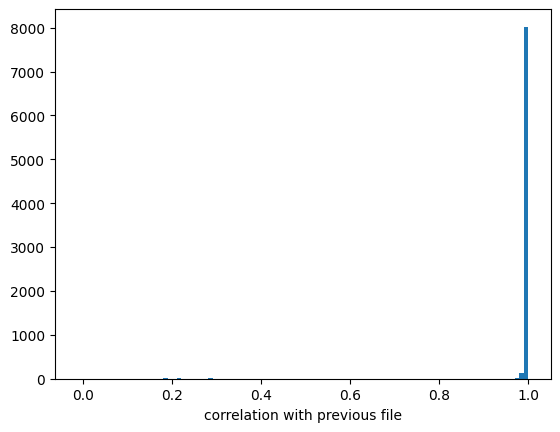

In [7]:
small = np.stack([np.array(Image.open(p).convert('L').resize((64, 64)), dtype=np.float32) for p in df.path])
z = (small - small.mean((1, 2), keepdims=True)) / (small.std((1, 2), keepdims=True) + 1e-6)
corr = (z[1:] * z[:-1]).mean((1, 2))   # similarity of each image to the previous one
plt.hist(corr, bins=100); plt.xlabel('correlation with previous file'); plt.show()

In [8]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
new_scan = np.r_[True, (corr < 0.8) | (df.label.values[1:] != df.label.values[:-1])]
h16 = np.stack([np.array(Image.fromarray(s.astype(np.uint8)).resize((16, 16)), dtype=float) for s in small])
df['phash'] = [np.packbits(x > x.mean()).tobytes().hex() for x in h16]

In [9]:
n, i = len(df), np.arange(len(df))
edges = [(a, b) for a, b in zip(i[:-1], i[1:]) if not new_scan[b]]
edges += [(g[0], x) for g in df.groupby('phash').indices.values() for x in g[1:]]
a, b = np.array(edges).T
df['scan'] = connected_components(coo_matrix((np.ones(len(a)), (a, b)), shape=(n, n)), directed=False)[1]
print('scan groups:', df.scan.nunique(), '| groups containing both labels:', (df.groupby('scan').label.nunique() > 1).sum())
df.groupby('label').scan.nunique()

scan groups: 116 | groups containing both labels: 0


label
Cyst      69
Normal    47
Name: scan, dtype: int64

### 1.3 Split by scan group (stratified by label)

In [10]:
from sklearn.model_selection import StratifiedGroupKFold
folds = list(StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42).split(df, df.label, df.scan))
df['split'] = 'train'
df.loc[folds[0][1], 'split'] = 'test'
df.loc[folds[1][1], 'split'] = 'val'
print('scans in more than one split:', (df.groupby('scan').split.nunique() > 1).sum())
pd.crosstab(df.split, df.label, margins=True)

scans in more than one split: 0


label,Cyst,Normal,All
split,,,
test,511,897,1408
train,2248,3417,5665
val,525,688,1213
All,3284,5002,8286


### 1.4 Save 224×224 copies

In [11]:
df['out'] = [os.path.join(DST, s, l, os.path.basename(p)) for s, l, p in zip(df.split, df.label, df.path)]
for p, o in zip(df.path, df.out): os.makedirs(os.path.dirname(o), exist_ok=True); ImageOps.pad(Image.open(p).convert('L'), (224, 224), color=0).save(o, quality=95)
df[['path', 'label', 'num', 'scan', 'split', 'out']].to_csv(os.path.join(DST, 'split.csv'), index=False)
print('saved', len(df), 'images to', DST)

saved 8286 images to dataset_224


## 2. Load the 224×224 images into memory
(Starts from `dataset_224/split.csv`, so section 1 does not need to be re-run.)

In [12]:
import torch, torch.nn as nn, torch.nn.functional as F, torchvision
from torchvision import transforms as T
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
torch.manual_seed(42); np.random.seed(42)
device

device(type='mps')

In [13]:
data = pd.read_csv('dataset_224/split.csv')
X = {s: torch.stack([T.functional.pil_to_tensor(Image.open(o)) for o in data[data.split == s].out]) for s in ['train', 'val', 'test']}
y = {s: torch.tensor((data[data.split == s].label == 'Cyst').values.astype(int)) for s in X}
{s: (tuple(X[s].shape), 'Normal/Cyst:', y[s].bincount().tolist()) for s in X}

{'train': ((5665, 1, 224, 224), 'Normal/Cyst:', [3417, 2248]),
 'val': ((1213, 1, 224, 224), 'Normal/Cyst:', [688, 525]),
 'test': ((1408, 1, 224, 224), 'Normal/Cyst:', [897, 511])}

## 3. Augmentation (training images only)
Light, realistic changes applied on the fly: small rotation, shift and zoom, plus brightness/contrast jitter (helps against the brightness difference between classes found in the EDA). No flips — left/right anatomy matters in CT. Validation and test images are never augmented.

Each image is also standardised on its own (zero mean, unit variance) and copied to 3 channels for the ImageNet-pretrained ResNet18.

In [14]:
augment = T.Compose([T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)), T.ColorJitter(brightness=0.2, contrast=0.2)])

def prep(x):   # uint8 (B,1,H,W) -> standardised float (B,3,H,W)
    x = x.float() / 255
    x = (x - x.mean((1, 2, 3), keepdim=True)) / (x.std((1, 2, 3), keepdim=True) + 1e-6)
    return x.repeat(1, 3, 1, 1)

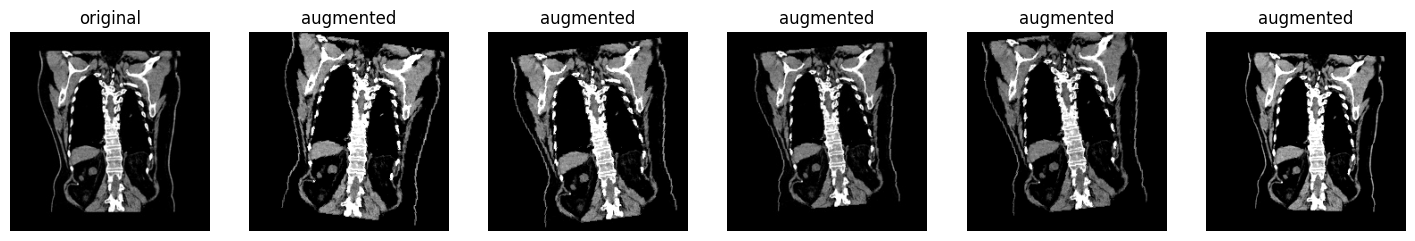

In [15]:
fig, axes = plt.subplots(1, 6, figsize=(18, 3))
axes[0].imshow(X['train'][0, 0], cmap='gray'); axes[0].set_title('original')
for ax in axes[1:]: ax.imshow(augment(X['train'][0])[0], cmap='gray'); ax.set_title('augmented')
for ax in axes: ax.axis('off')

## 4. Siamese network
Two images go through the **same** ResNet18 (shared weights) → two 512-d embeddings.  
A small head looks at `|e1 − e2|` and `e1 · e2` and predicts **same class (1) or different class (0)**.

In [16]:
class Siamese(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = torchvision.models.resnet18(weights='IMAGENET1K_V1')
        self.encoder.fc = nn.Identity()
        self.head = nn.Sequential(nn.Linear(1024, 256), nn.ReLU(), nn.Dropout(0.3), nn.Linear(256, 1))
    def embed(self, x): return self.encoder(x)
    def compare(self, e1, e2): return self.head(torch.cat([(e1 - e2).abs(), e1 * e2], 1)).squeeze(1)
    def forward(self, x1, x2): return self.compare(self.embed(x1), self.embed(x2))

### 4.1 Pairs
Half the pairs are same-class, half different-class. New random pairs every epoch; fixed pairs for validation.

In [17]:
def make_pairs(y, n, g):
    idx = [torch.where(y == c)[0] for c in (0, 1)]
    a = torch.randint(len(y), (n,), generator=g)
    same = torch.rand(n, generator=g) < 0.5
    other = torch.where(same, y[a], 1 - y[a])
    b = torch.stack([idx[c][torch.randint(len(idx[c]), (1,), generator=g)][0] for c in other.tolist()])
    return a, b, same.float()

### 4.2 Train

In [18]:
model = Siamese().to(device)
opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
EPOCHS, PAIRS, BS = 10, 4000, 32

In [19]:
def run_epoch(split, train, g):
    model.train(train)
    a, b, t = make_pairs(y[split], PAIRS if train else 1000, g)
    loss_sum, correct = 0.0, 0
    for k in range(0, len(a), BS):
        xa, xb, tk = X[split][a[k:k + BS]], X[split][b[k:k + BS]], t[k:k + BS]
        if train: xa, xb = torch.stack([augment(x) for x in xa]), torch.stack([augment(x) for x in xb])
        with torch.set_grad_enabled(train):
            logit = model(prep(xa).to(device), prep(xb).to(device))
            loss = F.binary_cross_entropy_with_logits(logit, tk.to(device))
        if train: opt.zero_grad(); loss.backward(); opt.step()
        loss_sum += loss.item() * len(tk); correct += ((logit > 0).float().cpu() == tk).sum().item()
    return loss_sum / len(a), correct / len(a)

In [20]:
import time
history, best, g = [], 1e9, torch.Generator().manual_seed(42)
for ep in range(EPOCHS):
    t0 = time.time()
    tr, va = run_epoch('train', True, g), run_epoch('val', False, torch.Generator().manual_seed(0))
    history.append((*tr, *va))
    if va[0] < best: best = va[0]; torch.save(model.state_dict(), 'siamese_best.pt')
    print(f'epoch {ep + 1:2d} | train loss {tr[0]:.3f} acc {tr[1]:.3f} | val loss {va[0]:.3f} acc {va[1]:.3f} | {time.time() - t0:.0f}s')

epoch  1 | train loss 0.249 acc 0.875 | val loss 0.094 acc 0.979 | 76s
epoch  2 | train loss 0.006 acc 0.999 | val loss 0.075 acc 0.977 | 75s
epoch  3 | train loss 0.006 acc 0.998 | val loss 1.063 acc 0.650 | 75s
epoch  4 | train loss 0.002 acc 1.000 | val loss 0.046 acc 0.994 | 75s
epoch  5 | train loss 0.009 acc 0.997 | val loss 1.119 acc 0.729 | 77s
epoch  6 | train loss 0.001 acc 1.000 | val loss 0.181 acc 0.911 | 75s
epoch  7 | train loss 0.001 acc 1.000 | val loss 1.093 acc 0.783 | 75s
epoch  8 | train loss 0.001 acc 1.000 | val loss 0.086 acc 0.969 | 75s
epoch  9 | train loss 0.000 acc 1.000 | val loss 0.072 acc 0.972 | 75s
epoch 10 | train loss 0.000 acc 1.000 | val loss 0.062 acc 0.980 | 75s


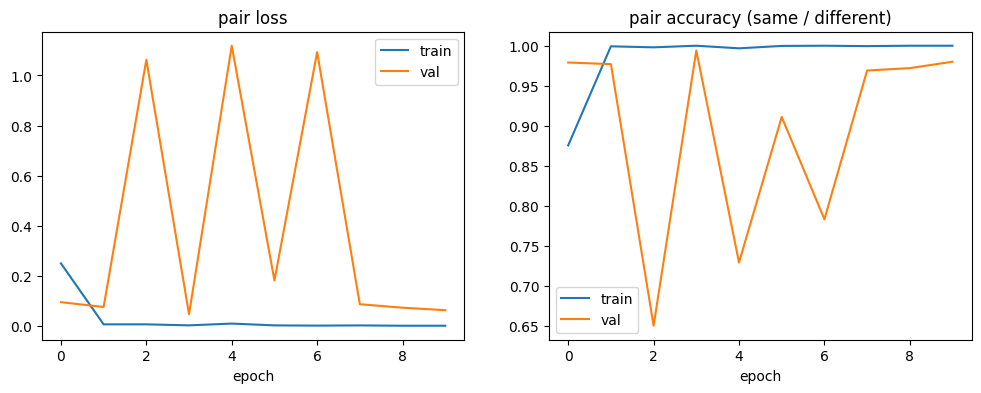

In [21]:
h = np.array(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(h[:, 0], label='train'); axes[0].plot(h[:, 2], label='val'); axes[0].set_title('pair loss')
axes[1].plot(h[:, 1], label='train'); axes[1].plot(h[:, 3], label='val'); axes[1].set_title('pair accuracy (same / different)')
for ax in axes: ax.set_xlabel('epoch'); ax.legend()

## 5. From Siamese to Normal-vs-Cyst classifier
Pick 30 reference images per class from the **training** set. A test image is compared with every reference; its score for a class is the average 'same' score against that class's references. Highest score wins.

Wrapping this as one `nn.Module` (image → 2 class scores) lets all XAI methods work on it.

In [22]:
class SiameseClassifier(nn.Module):
    def __init__(self, siamese, refs):
        super().__init__(); self.s, self.refs = siamese, refs
    def forward(self, x):
        e = self.s.embed(x)
        return torch.stack([self.s.compare(e.repeat_interleave(len(r), 0), r.repeat(len(e), 1)).view(len(e), len(r)).mean(1) for r in self.refs], 1)

In [23]:
model.load_state_dict(torch.load('siamese_best.pt', map_location=device)); model.eval()
gr = torch.Generator().manual_seed(1)
ref_idx = [torch.where(y['train'] == c)[0][torch.randperm(int((y['train'] == c).sum()), generator=gr)[:30]] for c in (0, 1)]
with torch.no_grad(): refs = [model.embed(prep(X['train'][i]).to(device)) for i in ref_idx]
clf = SiameseClassifier(model, refs).eval()

### 5.1 Test-set results

              precision    recall  f1-score   support

      Normal      0.952     0.920     0.935       897
        Cyst      0.867     0.918     0.892       511

    accuracy                          0.919      1408
   macro avg      0.909     0.919     0.914      1408
weighted avg      0.921     0.919     0.920      1408

ROC-AUC: 0.9832


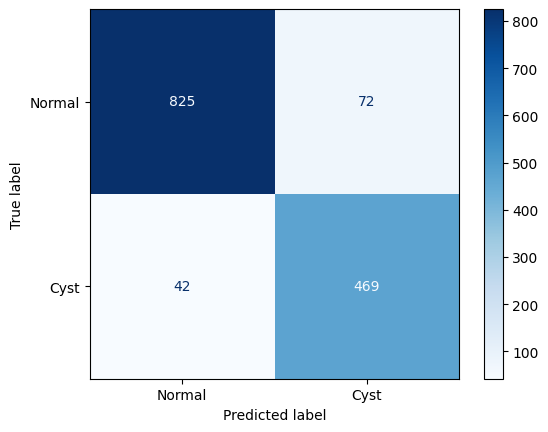

In [24]:
from sklearn.metrics import classification_report, roc_auc_score, ConfusionMatrixDisplay
with torch.no_grad(): scores = torch.cat([clf(prep(X['test'][k:k + 64]).to(device)).cpu() for k in range(0, len(X['test']), 64)])
pred = scores.argmax(1)
print(classification_report(y['test'], pred, target_names=CLASSES, digits=3))
print('ROC-AUC:', round(roc_auc_score(y['test'], scores[:, 1] - scores[:, 0]), 4))
ConfusionMatrixDisplay.from_predictions(y['test'], pred, display_labels=CLASSES, cmap='Blues');

## 6. Explainable AI
Explain 6 test images: 2 correctly predicted Cyst, 2 correctly predicted Normal, and up to 2 mistakes. Each map explains the **predicted** class.

In [25]:
ex = torch.cat([torch.where((y['test'] == c) & (pred == c))[0][:2] for c in (1, 0)] + [torch.where(y['test'] != pred)[0][:2]])
xs = prep(X['test'][ex]).to(device)
raw = X['test'][ex, 0].numpy() / 255
tgt = pred[ex]
titles = [f'true {CLASSES[y["test"][i]]} | pred {CLASSES[pred[i]]}' for i in ex]

In [26]:
def show_maps(maps, cmap='jet'):
    fig, axes = plt.subplots(len(ex), 1 + len(maps), figsize=(3 * (1 + len(maps)), 3 * len(ex)), squeeze=False)
    for r in range(len(ex)):
        axes[r, 0].imshow(raw[r], cmap='gray'); axes[r, 0].set_title(titles[r], fontsize=9)
        for k, (name, m) in enumerate(maps.items(), 1): axes[r, k].imshow(raw[r], cmap='gray'); axes[r, k].imshow(m[r], cmap=cmap, alpha=0.45); axes[r, k].set_title(name)
    for a in axes.flat: a.axis('off')
    plt.tight_layout(); plt.show()

### 6.1 CAM methods: Grad-CAM, Grad-CAM++, Score-CAM, LayerCAM
Computed on the last ResNet block (`layer4`).

100%|███████████████████████████████████████████████████████████████████████████████████| 32/32 [00:00<00:00, 39.12it/s]


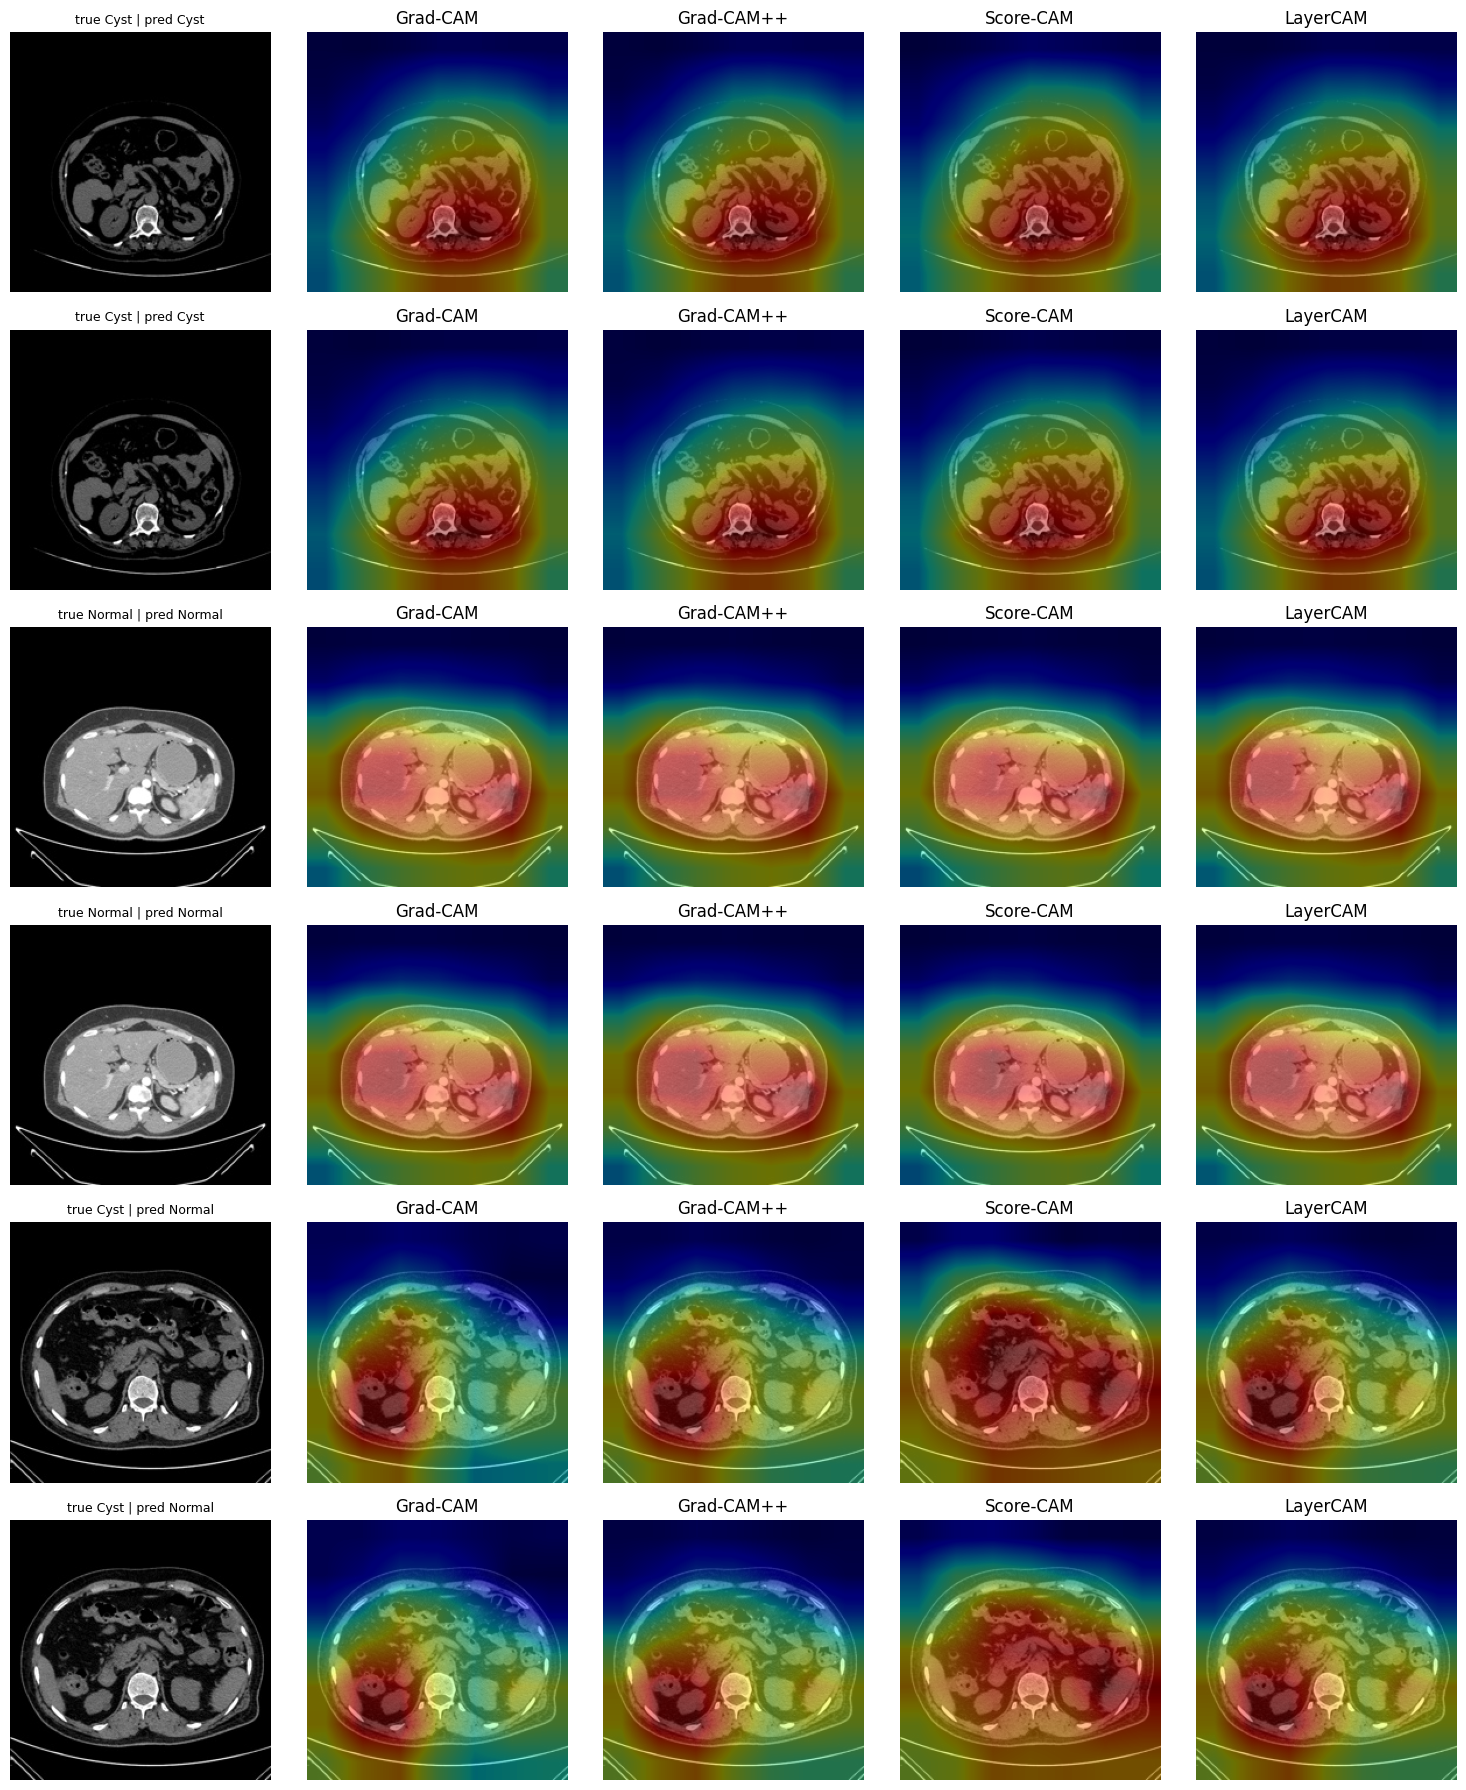

In [27]:
from pytorch_grad_cam import GradCAM, GradCAMPlusPlus, ScoreCAM, LayerCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
layer, targets = [model.encoder.layer4[-1]], [ClassifierOutputTarget(int(c)) for c in tgt]
cams = {name: m(model=clf, target_layers=layer)(input_tensor=xs, targets=targets) for name, m in {'Grad-CAM': GradCAM, 'Grad-CAM++': GradCAMPlusPlus, 'Score-CAM': ScoreCAM, 'LayerCAM': LayerCAM}.items()}
show_maps(cams)

### 6.2 Gradient & perturbation methods (Captum): Saliency, Integrated Gradients, GradientSHAP, Occlusion

In [28]:
from captum.attr import Saliency, IntegratedGradients, GradientShap, Occlusion
clf_cpu = SiameseClassifier(model.cpu(), [r.cpu() for r in refs]).eval()   # Captum is most reliable on CPU
xs_cpu, t_cpu = xs.cpu(), tgt.cpu()
attrs = {
    'Saliency': Saliency(clf_cpu).attribute(xs_cpu, target=t_cpu, abs=True),
    'Integrated Gradients': IntegratedGradients(clf_cpu).attribute(xs_cpu, baselines=xs_cpu * 0, target=t_cpu, n_steps=32, internal_batch_size=16),
    'GradientSHAP': GradientShap(clf_cpu).attribute(xs_cpu, baselines=prep(X['train'][ref_idx[0][:10]]), target=t_cpu, n_samples=16, stdevs=0.1),
    'Occlusion': Occlusion(clf_cpu).attribute(xs_cpu, target=t_cpu, sliding_window_shapes=(3, 32, 32), strides=(3, 16, 16), baselines=0),
}
model.to(device);

/Users/ahmad/Library/Python/3.9/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/ahmad/Library/Python/3.9/lib/python/site-packages/captum/attr/_core/saliency.py:129: UserWarning: Input Tensor 0 did not already require gradients, required_grads has been set automatically.
  gradient_mask = apply_gradient_requirements(inputs_tuple)


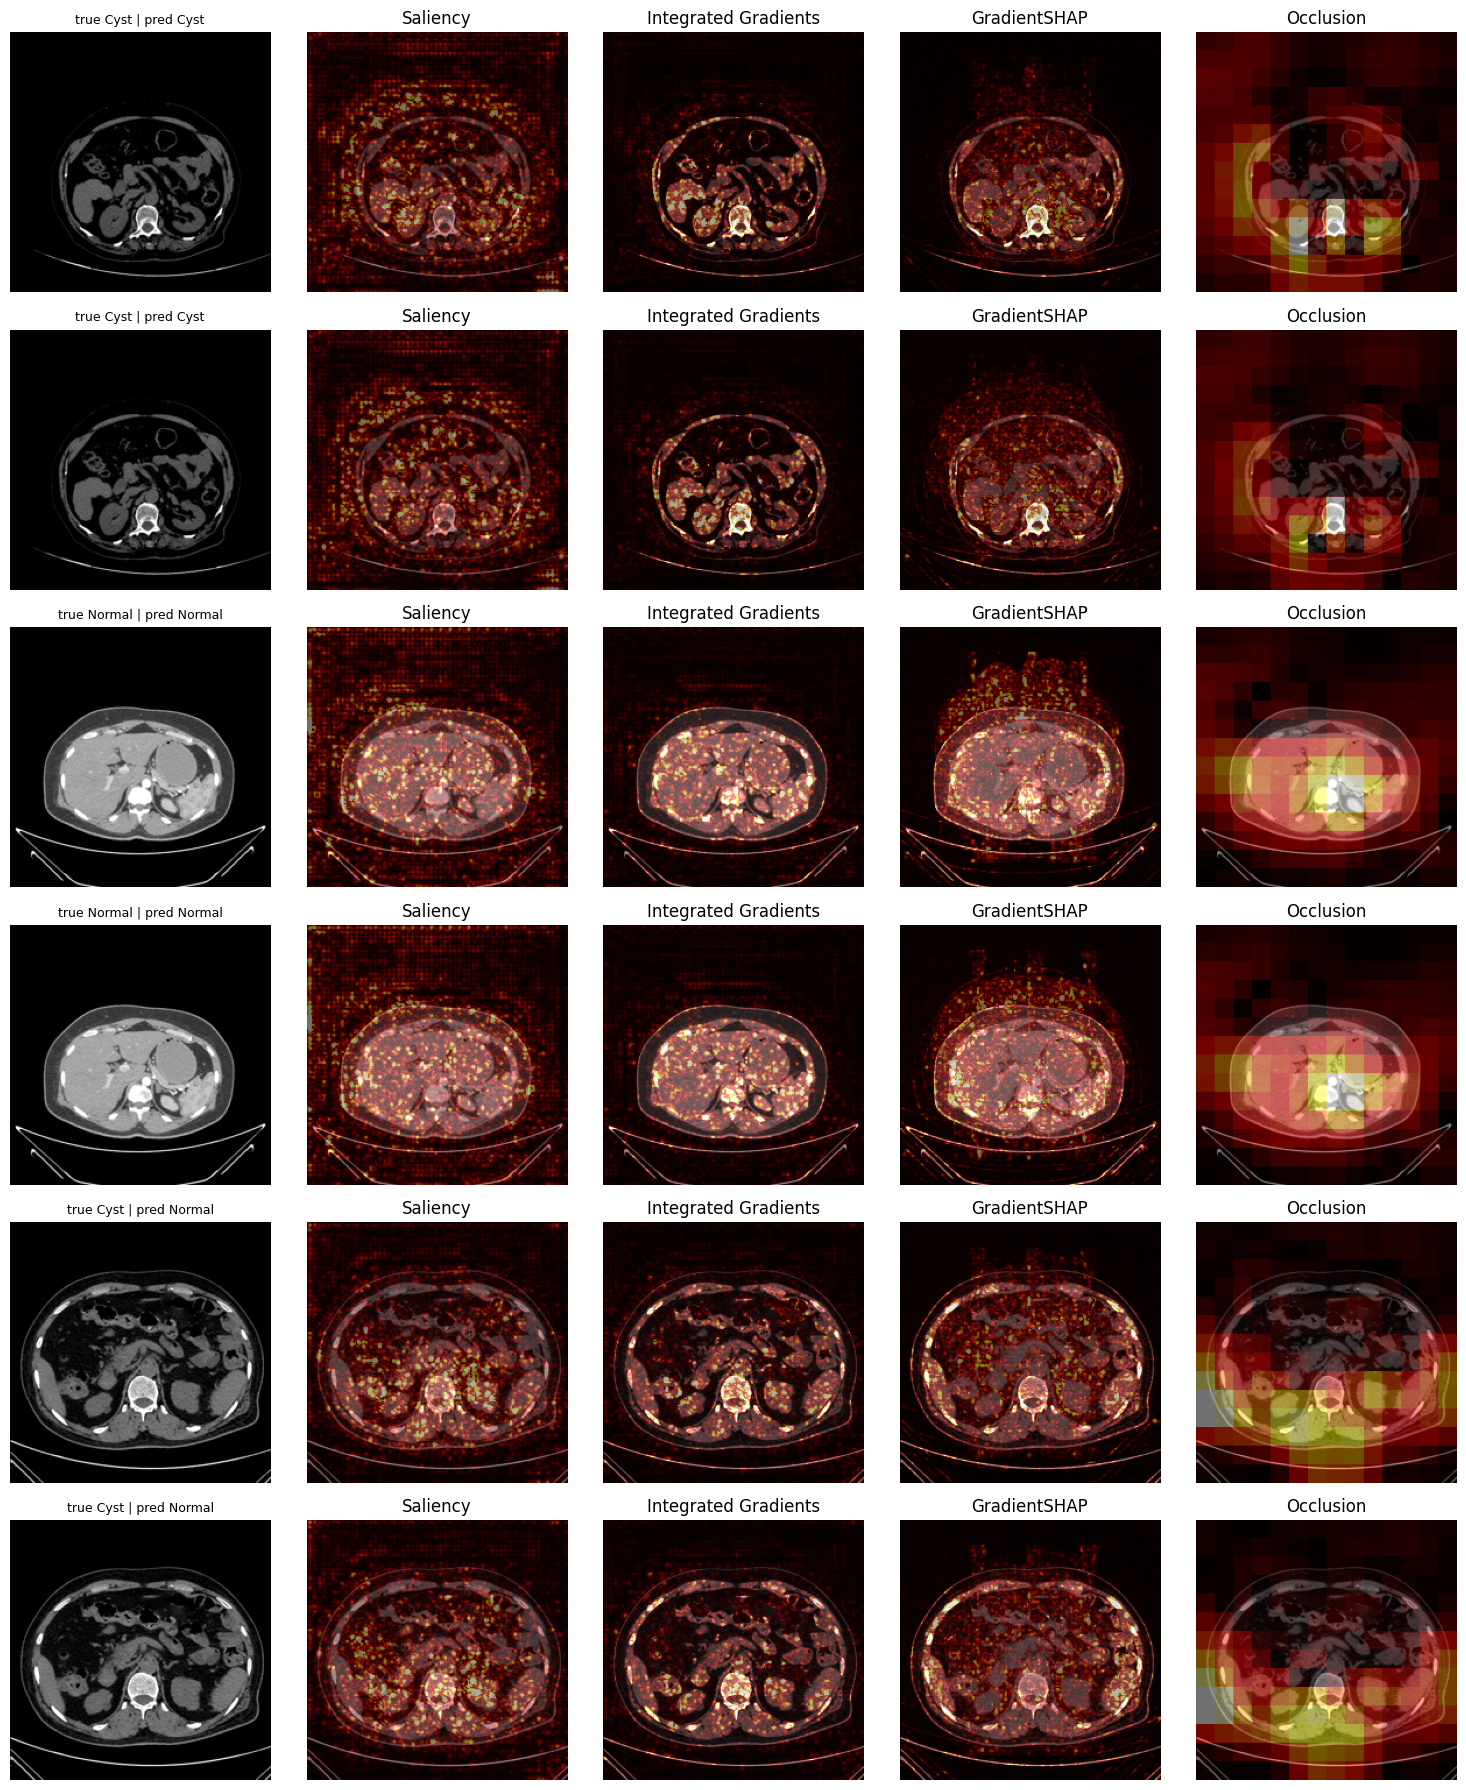

In [29]:
norm = lambda a: np.clip(a / (np.percentile(a, 99, axis=(1, 2), keepdims=True) + 1e-8), 0, 1)
show_maps({name: norm(a.abs().sum(1).detach().numpy()) for name, a in attrs.items()}, cmap='hot')

### 6.3 SHAP (Partition explainer, `shap` library)
Model-agnostic: hides image regions (by blurring) and measures how each region changes the class probability. Red = pushes towards that class, blue = pushes away.

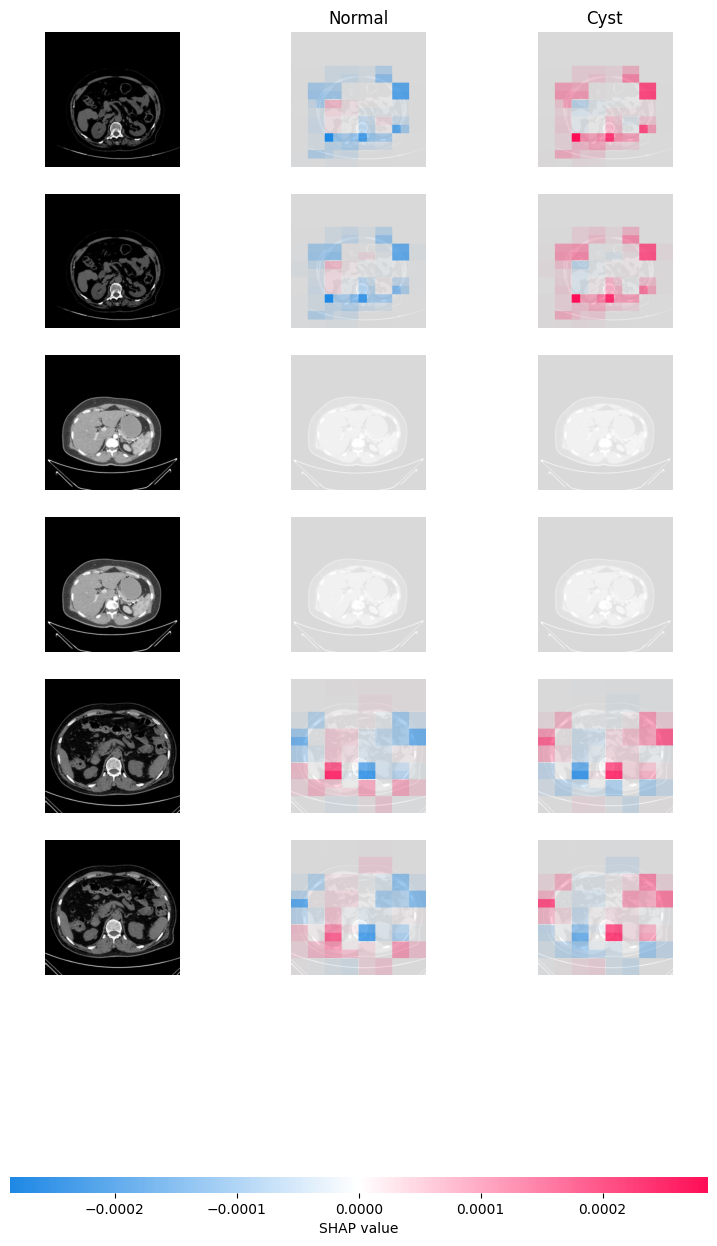

In [30]:
import shap
def f(imgs):   # numpy (N,224,224,3) in [0,1] -> class probabilities
    t = torch.tensor(imgs[..., :1], dtype=torch.float32).permute(0, 3, 1, 2) * 255
    with torch.no_grad(): return torch.softmax(clf(prep(t).to(device)), 1).cpu().numpy()
imgs = np.repeat(raw[..., None], 3, -1).astype(np.float32)
explainer = shap.Explainer(f, shap.maskers.Image('blur(32,32)', imgs[0].shape), output_names=CLASSES)
sv = explainer(imgs, max_evals=500, batch_size=50)
shap.image_plot(sv)